# 📘 3.1 Interpolation vs Extrapolation and Global vs Local Fitting

### Estimating values from engineering data without fooling yourself

In engineering, we often have data at a limited number of points:

* wind tunnel measurements at selected angles of attack,
* force-displacement data from a materials test,
* velocity measurements from a flight or rocket trajectory,
* pressure values from a CFD mesh,
* calibration measurements from a sensor.

Numerical methods help us estimate values **between** known data points, and sometimes beyond the measured range. The first case is usually much safer than the second.

This notebook introduces four important ideas:

1. **Interpolation** — estimating inside the measured data range.
2. **Extrapolation** — estimating outside the measured data range.
3. **Local fitting** — using nearby data points only.
4. **Global fitting** — fitting one model across the whole dataset.

These ideas will be used throughout Week 3, and they will also connect strongly to machine learning regression in Week 5.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* distinguish between **interpolation** and **extrapolation**;
* explain why extrapolation is usually more risky than interpolation;
* distinguish between **local** and **global** fitting methods;
* construct a simple local linear interpolant in Python;
* compare a local interpolant, a global interpolating polynomial, and a global least-squares polynomial fit;
* identify when a requested prediction lies outside the data domain.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The core ideas and examples in this notebook are based on:

* SciPy User Guide — [Interpolation (`scipy.interpolate`)](https://docs.scipy.org/doc/scipy/tutorial/interpolate.html)
* SciPy User Guide — [Extrapolation tips and tricks](https://docs.scipy.org/doc/scipy/tutorial/interpolate/extrapolation_examples.html)
* Python Numerical Methods — [Chapter 17: Interpolation](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.00-Interpolation.html)
* Python Numerical Methods — [Interpolation Problem Statement](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.01-Interpolation-Problem-Statement.html)
* LibreTexts / Autar Kaw — [Direct Method of Interpolation](https://math.libretexts.org/Workbench/Numerical_Methods_with_Applications_%28Kaw%29/5%3A_Interpolation/5.02%3A_Direct_Method_of_Interpolation)
* UBC — [The Runge Phenomenon and Piecewise Polynomial Interpolation](https://www.math.ubc.ca/~peirce/M406_Lecture_3_Runge_Phenon_Piecewise_Polynomial_Interpolation.pdf)
* NumPy Documentation — [Polynomial.fit](https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html)
* Holistic Numerical Methods — [Linear Interpolation video](https://nm.mathforcollege.com/chapter-05-02-linear-interpolation/)

## 📂 3.1.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.

The separate Week 3 workbook contains the activities to begin in Monday's workshop, continue in Wednesday's practical, and finish during revision at home.


### 📖 Core language for 3.1

Throughout this notebook:

* **data nodes** are the known coordinates and values;
* a **query point** is a location where a value is requested;
* the **data domain** is the supported range or region;
* **validation** means checking performance on information not used to construct the model.


## 📂 3.1.1 What problem are we solving?

Suppose we know a dependent variable $y$ at several independent variable values $x$:

$$ (x_0, y_0), (x_1, y_1), \dots, (x_n, y_n) $$

An **interpolation function** is a function $\hat{y}(x)$ that passes through the known data points:

$$
\hat{y}(x_i) = y_i
$$

for each data point.

This is useful when the data points are considered reliable and we need a value between the measured points.

> ### 📖 Definition: Interpolation
> **Interpolation** estimates values **inside** the range of known data.

> ### 📖 Definition: Extrapolation
> **Extrapolation** estimates values **outside** the range of known data.

### ⚠️ Point of note

Interpolation is not automatically correct, but it is usually more defensible than extrapolation.

Extrapolation depends on the assumption that the behaviour observed inside the measured range continues outside the measured range. This assumption often fails in engineering systems because real systems can change behaviour, saturate, stall, buckle, yield, separate, cavitate, heat up, or become unstable.

## 📂 3.1.2 Interpolation vs extrapolation

Assume the measured data covers the domain:

$$
x_\text{min} \le x \le x_\text{max}
$$

A requested prediction at $x^*$ is:

* an **interpolation** if:

$$
x_\text{min} \le x^* \le x_\text{max}
$$

* an **extrapolation** if:

$$
x^* < x_\text{min}
$$

or:

$$
x^* > x_\text{max}
$$

In code, this is one of the first checks we should make before trusting a prediction.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import make_interp_spline
from numpy.polynomial import Polynomial

pd.set_option("display.precision", 3)

## 📂 3.1.3 Example dataset: rocket velocity

We will use an aerospace-style example adapted from the LibreTexts / Autar Kaw numerical methods material.

The data gives the upward velocity of a rocket at selected times.

This is a useful interpolation example because engineers often have sampled time-history data from:

* experiments,
* flight tests,
* simulations,
* sensor logs,
* control-system outputs.

### Data source

Adapted from:

Autar Kaw, *Numerical Methods with Applications*, LibreTexts, Section 5.02: Direct Method of Interpolation.  
Source: https://math.libretexts.org/Workbench/Numerical_Methods_with_Applications_%28Kaw%29/5%3A_Interpolation/5.02%3A_Direct_Method_of_Interpolation

In [ ]:
# Rocket velocity data
# Source: Autar Kaw / LibreTexts numerical methods example

time_s = np.array([0, 10, 15, 20, 22.5, 30], dtype=float)
velocity_ms = np.array([0, 227.04, 362.78, 517.35, 602.97, 901.67], dtype=float)

rocket_data = pd.DataFrame({
    "time_s": time_s,
    "velocity_ms": velocity_ms
})

rocket_data

,time_s,velocity_ms
0,0.0,0.00
1,10.0,227.04
2,15.0,362.78
3,20.0,517.35
4,22.5,602.97
5,30.0,901.67


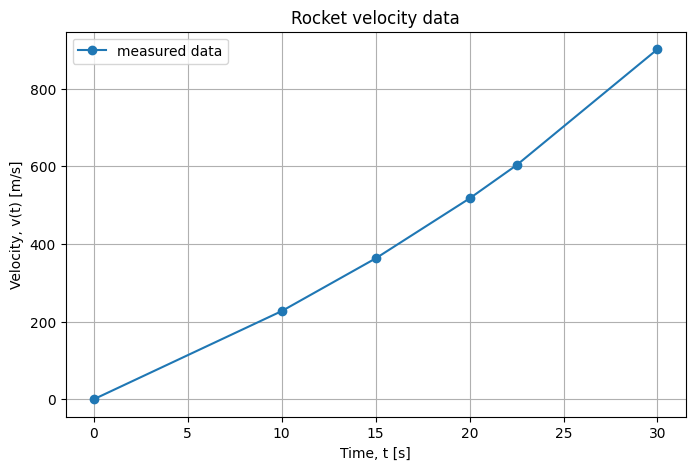

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(time_s, velocity_ms, "o-", label="measured data")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Velocity, v(t) [m/s]")
ax.set_title("Rocket velocity data")
ax.grid(True)
ax.legend()

plt.show()

> ### 🧩 Code Explanation
>
> The data is stored in two NumPy arrays:
>
> * `time_s` contains the independent variable, time in seconds.
> * `velocity_ms` contains the dependent variable, velocity in metres per second.
>
> The `pandas.DataFrame` is used only to display the data clearly.
>
> The plot shows that the velocity increases **nonlinearly**. We should **not** assume that a straight line through all points is the right model.

## 📂 3.1.4 Checking whether a prediction is interpolation or extrapolation

Before choosing a numerical method, we should check the prediction location.

For this dataset:

$$
0 \le t \le 30
$$

So:

* predicting at $t=16$ s is interpolation;
* predicting at $t=35$ s is extrapolation.

In [ ]:
def prediction_region(x_query, x_data):
    """
    Classify query points as interpolation or extrapolation.

    Parameters
    ----------
    x_query : float or array-like
        Point or points where a prediction is requested.

    x_data : array-like
        Known independent-variable data points.

    Returns
    -------
    str or ndarray
        "interpolation" if the query point lies inside the data range,
        otherwise "extrapolation".
    """
    x_query = np.atleast_1d(x_query).astype(float)
    x_data = np.asarray(x_data, dtype=float)

    x_min = np.min(x_data)
    x_max = np.max(x_data)

    labels = np.where(
        (x_query >= x_min) & (x_query <= x_max),
        "interpolation",
        "extrapolation"
    )

    if labels.size == 1:
        return labels[0]

    return labels


query_times = np.array([12, 16, 25, 35], dtype=float)

region_table = pd.DataFrame({
    "query_time_s": query_times,
    "region": prediction_region(query_times, time_s)
})

region_table

,query_time_s,region
0,12.0,interpolation
1,16.0,interpolation
2,25.0,interpolation
3,35.0,extrapolation


### ⚠️ Point of note

A numerical method may still return a number for an extrapolation point.

That does **not** mean the number is reliable.

A good engineering workflow should flag extrapolation before reporting the result.

## 📂 3.1.5 Local vs global fitting

There are two broad ways to build an approximation from data.

### 🔹 Local fitting

A **local** method uses nearby data points to estimate the value.

For example, local linear interpolation uses the two data points that bracket the requested value.

This is common in engineering lookup tables.

Advantages:

* simple;
* predictable;
* local changes in data only affect nearby intervals;
* often robust for tabulated engineering data.

Disadvantages:

* may not be smooth;
* can miss global trends;
* may give poor derivative estimates.

### 🔹 Global fitting

A **global** method fits one function across the whole dataset.

For example, a polynomial fitted across all data points is global.

Advantages:

* compact mathematical expression;
* can be smooth;
* can capture broad trends.

Disadvantages:

* one changed data point can affect the whole curve;
* high-degree global polynomials can oscillate badly;
* extrapolation can look smooth but be very wrong.

> ### ⚠️ Point of note
>
> A curve passing exactly through all data points is not necessarily a good model of the engineering system.
>
> We will explore this more in Notebook 3.2 when we discuss noise and overfitting.

## 📂 3.1.6 Comparing three methods

We will compare:

1. **Local linear interpolation**  
   A piecewise linear interpolant. It joins neighbouring data points with straight lines.

2. **Global polynomial interpolation**  
   A single polynomial passing through all data points.

3. **Global quadratic least-squares fit**  
   A single degree-2 polynomial that approximates the data but does not necessarily pass through every point.

### Important distinction

The first two are interpolation methods because they pass through the data points.

The third is a fitting or approximation method, not a true interpolation method, because it does not necessarily pass exactly through the data.

In [ ]:
# Local linear interpolant
# k=1 means first-order piecewise polynomial, i.e. straight-line segments.
local_linear = make_interp_spline(time_s, velocity_ms, k=1)

# Global polynomial interpolant
# With 6 data points, a degree-5 polynomial can pass through all points.
global_polynomial = Polynomial.fit(
    time_s,
    velocity_ms,
    deg=len(time_s) - 1,
    domain=[time_s.min(), time_s.max()]
)

# Global quadratic least-squares fit
# This is an approximation, not an exact interpolant.
global_quadratic = Polynomial.fit(
    time_s,
    velocity_ms,
    deg=2,
    domain=[time_s.min(), time_s.max()]
)

# Evaluate all methods at selected points
query_times = np.array([12, 16, 25, 35], dtype=float)

comparison_table = pd.DataFrame({
    "time_s": query_times,
    "region": prediction_region(query_times, time_s),
    "local_linear_ms": local_linear(query_times),
    "global_polynomial_ms": global_polynomial(query_times),
    "global_quadratic_ms": global_quadratic(query_times)
})

comparison_table

,time_s,region,local_linear_ms,global_polynomial_ms,global_quadratic_ms
0,12.0,interpolation,281.336,279.297,275.125
1,16.0,interpolation,393.694,392.071,391.488
2,25.0,interpolation,702.537,695.011,699.671
3,35.0,extrapolation,1100.803,1145.414,1117.391


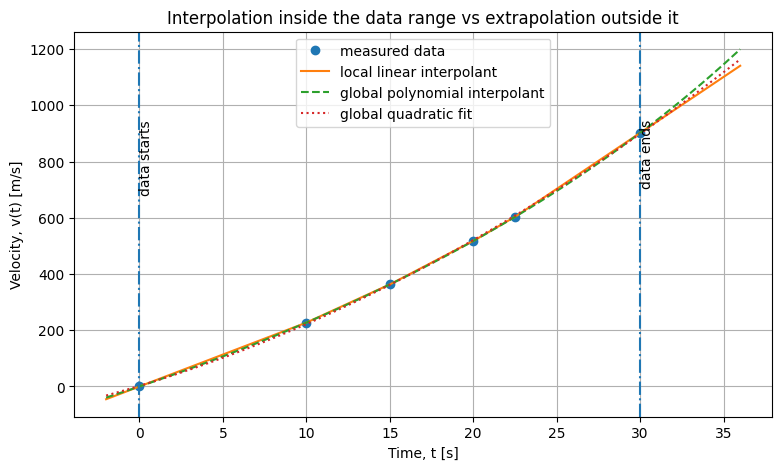

In [ ]:
x_plot = np.linspace(-2, 36, 400)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(time_s, velocity_ms, "o", label="measured data")
ax.plot(x_plot, local_linear(x_plot), label="local linear interpolant")
ax.plot(x_plot, global_polynomial(x_plot), "--", label="global polynomial interpolant")
ax.plot(x_plot, global_quadratic(x_plot), ":", label="global quadratic fit")

# Mark the data domain
ax.axvline(time_s.min(), linestyle="-.")
ax.axvline(time_s.max(), linestyle="-.")

ax.text(time_s.min(), 950, "data starts", rotation=90, va="top")
ax.text(time_s.max(), 950, "data ends", rotation=90, va="top")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Velocity, v(t) [m/s]")
ax.set_title("Interpolation inside the data range vs extrapolation outside it")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

Inside the data range, the different methods may give similar but not identical values.

Outside the data range, the methods can diverge more strongly.

That does not mean one extrapolated value is automatically correct. It means each method is making a different assumption about what happens beyond the measured domain.

> ### ⚠️ Engineering warning
>
> Extrapolation should normally be supported by physics, extra validation data, or a clearly stated engineering assumption.
>
> A smooth-looking curve is not evidence that the extrapolated prediction is physically meaningful.

## 📂 3.1.7 How local and global methods respond to a changed data point

One reason engineers often like local interpolation for lookup tables is that changes remain local.

Suppose one measurement changes. This could happen because:

* a sensor was recalibrated;
* a data-entry error was corrected;
* a test condition was repeated;
* a simulation was rerun with a higher-fidelity model.

A local method should mostly change near that point.

A global method may change everywhere.

In [ ]:
# Controlled perturbation test:
# Increase one velocity data point by 80 m/s.
# This is not claiming the original data is wrong; it is just a sensitivity test.

velocity_perturbed = velocity_ms.copy()
velocity_perturbed[3] += 80.0   # perturb value at t = 20 s

local_linear_perturbed = make_interp_spline(time_s, velocity_perturbed, k=1)

global_polynomial_perturbed = Polynomial.fit(
    time_s,
    velocity_perturbed,
    deg=len(time_s) - 1,
    domain=[time_s.min(), time_s.max()]
)

comparison_points = np.array([5, 12, 16, 25], dtype=float)

sensitivity_table = pd.DataFrame({
    "time_s": comparison_points,
    "local_change_ms": local_linear_perturbed(comparison_points) - local_linear(comparison_points),
    "global_change_ms": global_polynomial_perturbed(comparison_points) - global_polynomial(comparison_points)
})

sensitivity_table

,time_s,local_change_ms,global_change_ms
0,5.0,0.0,350.000
1,12.0,0.0,-43.546
2,16.0,16.0,27.955
3,25.0,0.0,-150.000


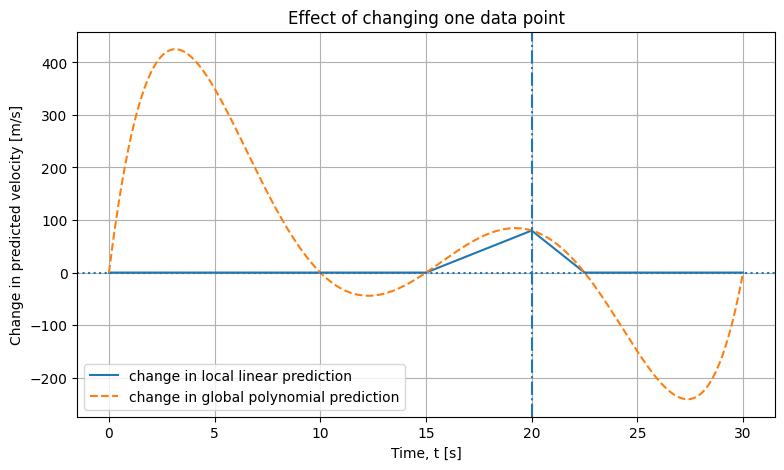

In [ ]:
x_plot = np.linspace(time_s.min(), time_s.max(), 400)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    x_plot,
    local_linear_perturbed(x_plot) - local_linear(x_plot),
    label="change in local linear prediction"
)

ax.plot(
    x_plot,
    global_polynomial_perturbed(x_plot) - global_polynomial(x_plot),
    "--",
    label="change in global polynomial prediction"
)

ax.axhline(0, linestyle=":")
ax.axvline(time_s[3], linestyle="-.")

ax.set_xlabel("Time, t [s]")
ax.set_ylabel("Change in predicted velocity [m/s]")
ax.set_title("Effect of changing one data point")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The local linear method changes mainly near the modified data point.

The global polynomial changes across a much larger part of the domain.

This is one reason high-degree global interpolation needs care. Even when the curve passes through all data points, it may behave poorly between points, near the boundaries, or outside the data range.

This issue is related to **Runge's phenomenon**, where high-degree polynomial interpolation can oscillate strongly. We will not derive this here, but it is one of the reasons spline methods and piecewise methods are widely used in practical numerical analysis.

## 📂 3.1.8 Worked extension — build a prediction safety check

Run the completed demonstration below.

Your function should:

1. accept a query time;
2. return the predicted velocity using local linear interpolation;
3. print a warning if the query time requires extrapolation.

### 🧾 Instructions

The safety checks are completed so the cell runs without editing.

Suggested test cases:

* `safe_velocity_prediction(16)` should be interpolation.
* `safe_velocity_prediction(35)` should print an extrapolation warning.

In [ ]:
# Demonstration setting: Complete this function.

def safe_velocity_prediction(t_query):
    """
    Predict rocket velocity and warn if extrapolation is being used.

    Parameters
    ----------
    t_query : float
        Query time in seconds.

    Returns
    -------
    float
        Predicted velocity in m/s.
    """

    # Demonstration setting: classify the query point
    region = prediction_region(t_query, time_s)

    # Demonstration setting: evaluate the local linear interpolant
    predicted_velocity = float(local_linear(t_query))

    # Demonstration setting: print a warning if the query is extrapolation
    if region == "extrapolation":
        print("Warning: this prediction is extrapolation and should be treated with caution.")

    return predicted_velocity


# Try your function here
safe_velocity_prediction(16)

393.694

## 📂 3.1.9 Worked extension — compare methods at your own query points

Choose three query times:

1. one inside the data range and close to a known data point;
2. one inside the data range but between data points;
3. one outside the data range.

Then compare the three methods from this notebook.

### Questions

1. Which predictions are interpolation?
2. Which predictions are extrapolation?
3. Which method gives the largest prediction at the extrapolated point?
4. Would you be comfortable reporting the extrapolated value in an engineering calculation? Why or why not?

In [ ]:
# Demonstration setting: Replace these values with your own query times.

my_query_times = np.array([
    12.0,
    16.0,
    35.0
], dtype=float)

my_comparison_table = pd.DataFrame({
    "time_s": my_query_times,
    "region": prediction_region(my_query_times, time_s),
    "local_linear_ms": local_linear(my_query_times),
    "global_polynomial_ms": global_polynomial(my_query_times),
    "global_quadratic_ms": global_quadratic(my_query_times)
})

my_comparison_table